# 06. Các mô hình tự cài đặt bằng NumPy
Đúng như phiếu đăng ký đề tài, 4 thuật toán hồi quy được **tự cài đặt bằng NumPy** (`src/mo_hinh_tu_code.py`, không dùng thư viện học máy) và đối chiếu kết quả với scikit-learn:

1. Linear Regression – nghiệm dạng đóng
2. Linear Regression – Gradient Descent
3. Ridge Regression
4. Kernel Ridge Regression với kernel RBF

Biến mục tiêu: log(giá). Chọn siêu tham số trên tập validation, báo cáo trên tập test. Chỉ số: RMSE và R² trên thang log; MAE (tỷ đồng), MAPE và tỉ lệ dự đoán lệch không quá ±10% / ±20% giá thật (hàm `chi_so` trong `src/danh_gia.py`).

In [1]:
import sys, os, time, json
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.kernel_ridge import KernelRidge
from mo_hinh_tu_code import *
from danh_gia import chi_so, theo_nhom

pd.set_option('display.width', 170)
sns.set_theme(style='whitegrid')
FIG = '../reports/figures'
doc = lambda t: pd.read_parquet(f'../data/processed/dac_trung_{t}.parquet')
tr, va, te, tm = doc('train'), doc('val'), doc('test'), doc('train_tang_mau')
COT_X = [c for c in tr.columns if c not in ('y', 'trong_so') and not c.startswith('_')]
f64 = lambda a: a.astype(np.float64)
X_tr, y_tr, w_tr = f64(tr[COT_X].values), f64(tr['y'].values), f64(tr['trong_so'].values)
X_va, y_va = f64(va[COT_X].values), f64(va['y'].values)
X_te, y_te = f64(te[COT_X].values), f64(te['y'].values)
print('Số đặc trưng:', len(COT_X), '| train', X_tr.shape, '| val', X_va.shape, '| test', X_te.shape, '| train tăng mẫu', tm.shape)

ket_qua = {}
du_doan_val, du_doan_test = {}, {}
def ghi_ket_qua(ten, mh, t_fit):
    du_doan_val[ten], du_doan_test[ten] = mh.predict(X_va), mh.predict(X_te)
    ket_qua[ten] = {**{f'val {k}': v for k, v in chi_so(y_va, du_doan_val[ten]).items() if k in ('RMSE log', 'MAPE (%)')},
                    **chi_so(y_te, du_doan_test[ten]), 'Thời gian huấn luyện (s)': t_fit}
    print(ten, {k: round(v, 4) for k, v in ket_qua[ten].items()})

class TrungBinh:
    def fit(self, X, y):
        self.m = y.mean(); return self
    def predict(self, X):
        return np.full(len(X), self.m)
ghi_ket_qua('Mốc so sánh: dự đoán bằng trung bình', TrungBinh().fit(X_tr, y_tr), 0.0)

Số đặc trưng: 44 | train (604466, 44) | val (129529, 44) | test (129529, 44) | train tăng mẫu (738661, 51)
Mốc so sánh: dự đoán bằng trung bình {'val RMSE log': 1.0863, 'val MAPE (%)': 128.6385, 'RMSE log': 1.0882, 'R² log': -0.0, 'MAE (tỷ)': 10.3365, 'MAPE (%)': 129.2073, 'Trung vị APE (%)': 59.9165, 'Lệch ≤10% (%)': 10.1444, 'Lệch ≤20% (%)': 18.9178, 'Thời gian huấn luyện (s)': 0.0}


## 1. Linear Regression tự code – nghiệm dạng đóng
$\tilde X = [\mathbf 1, X]$, $\; w = (\tilde X^T \tilde X)^{-1} \tilde X^T y$ (giải hệ tuyến tính bằng `np.linalg.solve` thay vì nghịch đảo trực tiếp để ổn định số học). Dữ liệu dùng kiểu float64: thử nghiệm cho thấy nếu đưa float32 vào sklearn thì hệ số lệch tới ~0,75 so với nghiệm chính xác do sai số làm tròn, còn float64 thì khớp tới 1e-13.

In [2]:
t = time.time(); lr = HoiQuyTuyenTinh().fit(X_tr, y_tr); t_lr = time.time() - t
ghi_ket_qua('Linear Regression (tự code, nghiệm đóng)', lr, t_lr)
sk = LinearRegression().fit(X_tr, y_tr)
print('Đối chiếu sklearn - chênh lệch lớn nhất của hệ số:', float(np.max(np.abs(np.r_[sk.intercept_, sk.coef_] - lr.w))),
      '| của dự đoán trên test:', float(np.max(np.abs(sk.predict(X_te) - lr.predict(X_te)))))

Linear Regression (tự code, nghiệm đóng) {'val RMSE log': 0.4954, 'val MAPE (%)': 41.2042, 'RMSE log': 0.4931, 'R² log': 0.7946, 'MAE (tỷ)': 5.4855, 'MAPE (%)': 41.0941, 'Trung vị APE (%)': 25.4314, 'Lệch ≤10% (%)': 21.2864, 'Lệch ≤20% (%)': 40.6133, 'Thời gian huấn luyện (s)': 0.1255}


Đối chiếu sklearn - chênh lệch lớn nhất của hệ số: 1.1945999744966684e-13 | của dự đoán trên test: 7.815970093361102e-13


## 2. Linear Regression bằng Gradient Descent tự code
$\nabla L = \frac{2}{N} \tilde X^T(\tilde X w - y)$, $\; w \leftarrow w - \eta \nabla L$.

Ma trận Hessian $H = \frac{2}{N}\tilde X^T \tilde X$ không đổi; GD chỉ hội tụ khi $\eta < 2 / \lambda_{max}(H)$. Tốc độ hội tụ phụ thuộc số điều kiện $\kappa = \lambda_{max}/\lambda_{min}$ – các đặc trưng target encoding tương quan cao làm $\kappa$ lớn nên GD tiến về nghiệm đóng chậm ở một số hướng.

λmax(H) = 16.472, λmin(H) = 0.0317, số điều kiện κ = 520
=> GD hội tụ khi η < 2/λmax = 0.1214


Thử η = 2.2/λmax = 0.1336 (vượt ngưỡng): MSE sau 1, 10, 25 vòng = ['278', '9.98', '2.06e+03'] -> phân kỳ


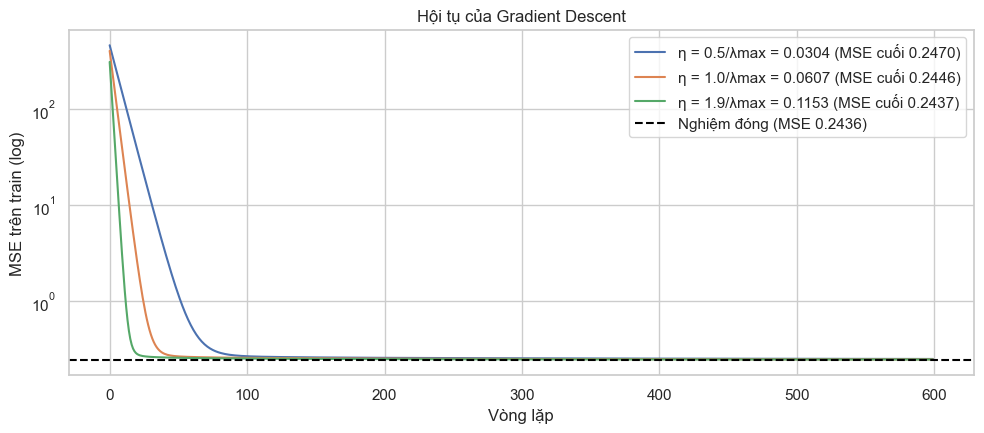

Linear Regression (tự code, GD, η=0.1153) {'val RMSE log': 0.4955, 'val MAPE (%)': 41.1994, 'RMSE log': 0.4933, 'R² log': 0.7945, 'MAE (tỷ)': 5.4884, 'MAPE (%)': 41.0872, 'Trung vị APE (%)': 25.4208, 'Lệch ≤10% (%)': 21.3087, 'Lệch ≤20% (%)': 40.5623, 'Thời gian huấn luyện (s)': 19.0836}
Chênh lệch trọng số GD so với nghiệm đóng (lớn nhất): 0.07163222132529234


In [3]:
mse_dong = float(np.mean((lr.predict(X_tr) - y_tr) ** 2))
Xb = them_cot_1(X_tr)
tri_rieng = np.linalg.eigvalsh(2 * Xb.T @ Xb / len(Xb))
del Xb
L_MAX = float(tri_rieng[-1])
print(f'λmax(H) = {L_MAX:.3f}, λmin(H) = {tri_rieng[0]:.4f}, số điều kiện κ = {L_MAX / tri_rieng[0]:.0f}')
print(f'=> GD hội tụ khi η < 2/λmax = {2 / L_MAX:.4f}')
thu = HoiQuyGradientDescent(toc_do_hoc=2.2 / L_MAX, so_vong=25).fit(X_tr, y_tr)
print(f'Thử η = 2.2/λmax = {2.2 / L_MAX:.4f} (vượt ngưỡng): MSE sau 1, 10, 25 vòng =', [f'{thu.lich_su[i]:.3g}' for i in (0, 9, 24)], '-> phân kỳ')
plt.figure(figsize=(10, 4.5))
gd_tot = None
for he_so in [0.5, 1.0, 1.9]:
    eta = he_so / L_MAX
    t = time.time(); gd = HoiQuyGradientDescent(toc_do_hoc=eta, so_vong=600).fit(X_tr, y_tr); t_gd = time.time() - t
    plt.plot(gd.lich_su, label=f'η = {he_so}/λmax = {eta:.4f} (MSE cuối {gd.lich_su[-1]:.4f})')
    if gd_tot is None or gd.lich_su[-1] < gd_tot[0].lich_su[-1]:
        gd_tot = (gd, round(eta, 4), t_gd)
plt.axhline(mse_dong, color='black', ls='--', label=f'Nghiệm đóng (MSE {mse_dong:.4f})')
plt.yscale('log'); plt.xlabel('Vòng lặp'); plt.ylabel('MSE trên train (log)'); plt.legend(); plt.title('Hội tụ của Gradient Descent')
plt.tight_layout(); plt.savefig(f'{FIG}/06_gradient_descent.png', dpi=120); plt.show()
ghi_ket_qua(f'Linear Regression (tự code, GD, η={gd_tot[1]})', gd_tot[0], gd_tot[2])
print('Chênh lệch trọng số GD so với nghiệm đóng (lớn nhất):', float(np.max(np.abs(gd_tot[0].w - lr.w))))

## 3. Ridge Regression tự code
$w = (X_c^T X_c + \lambda I)^{-1} X_c^T y_c$ với $X_c, y_c$ đã trừ trung bình (không phạt hệ số chặn), $b = \bar y - \bar x^T w$. Chọn λ theo tập validation.

In [4]:
chon_lam = {}
for lam in [0.01, 1, 100, 1e4, 1e5, 1e6]:
    rd = HoiQuyRidge(lam).fit(X_tr, y_tr)
    chon_lam[lam] = chi_so(y_va, rd.predict(X_va))['RMSE log']
chon_lam = pd.Series(chon_lam, name='RMSE val')
lam_tot = float(chon_lam.idxmin())
print(chon_lam.round(5).to_string())
t = time.time(); ridge = HoiQuyRidge(lam_tot).fit(X_tr, y_tr); t_rd = time.time() - t
ghi_ket_qua(f'Ridge (tự code, λ={lam_tot:g})', ridge, t_rd)
sk = Ridge(alpha=lam_tot).fit(X_tr, y_tr)
print('Đối chiếu sklearn Ridge - chênh lệch lớn nhất của hệ số:', float(np.max(np.abs(sk.coef_ - ridge.w))))

0.01          0.49535
1.00          0.49535
100.00        0.49536
10000.00      0.49935
100000.00     0.53399
1000000.00    0.72150
Ridge (tự code, λ=0.01) {'val RMSE log': 0.4954, 'val MAPE (%)': 41.2042, 'RMSE log': 0.4931, 'R² log': 0.7946, 'MAE (tỷ)': 5.4855, 'MAPE (%)': 41.0941, 'Trung vị APE (%)': 25.4315, 'Lệch ≤10% (%)': 21.2864, 'Lệch ≤20% (%)': 40.6133, 'Thời gian huấn luyện (s)': 0.1452}


Đối chiếu sklearn Ridge - chênh lệch lớn nhất của hệ số: 7.327471962526033e-15


## 4. Kernel Ridge Regression (RBF) tự code
$\alpha = (K + \lambda I)^{-1}(y - \bar y)$, $\; \hat y(x) = \sum_i \alpha_i k(x, x_i) + \bar y$, $\; k(x, z) = \exp(-\gamma \lVert x - z \rVert^2)$.

Ma trận nhân $K$ có kích thước $n \times n$: với 600.000 mẫu cần khoảng 2,9 TB bộ nhớ và độ phức tạp giải hệ $O(n^3)$ – không khả thi. Vì vậy Kernel Ridge được huấn luyện trên **mẫu con phân tầng** và khảo sát ảnh hưởng của kích thước mẫu con.

In [5]:
def mau_con(n, seed=42):
    rng = np.random.default_rng(seed)
    return np.concatenate([rng.choice(chi_so_nhom, max(1, int(round(n * len(chi_so_nhom) / len(tr)))), replace=False)
                           for chi_so_nhom in tr.groupby('_loai_bds').indices.values()])
i_tune = mau_con(4000)
j_tune = np.random.default_rng(1).choice(len(X_va), 5000, replace=False)
luoi = {}
for gamma in [0.005, 0.01, 0.02, 0.05]:
    for lam in [0.1, 1.0, 10.0]:
        k = KernelRidgeRBF(gamma, lam).fit(X_tr[i_tune], y_tr[i_tune])
        luoi[(gamma, lam)] = chi_so(y_va[j_tune], k.predict(X_va[j_tune]))['RMSE log']
luoi = pd.Series(luoi).unstack()
luoi.index.name, luoi.columns.name = 'γ', 'λ'
gamma_tot, lam_krr = luoi.stack().idxmin()
print('Chọn γ =', gamma_tot, ', λ =', lam_krr)
luoi.round(4)

Chọn γ = 0.005 , λ = 0.1


λ,0.1,1.0,10.0
γ,,,
0.005,0.4836,0.4959,0.5751
0.010,0.4928,0.4995,0.5660
0.020,0.5109,0.5171,0.5935
0.050,0.5641,0.5818,0.6919


In [6]:
quy_mo = {}
for n in [1000, 2000, 4000, 8000]:
    idx = mau_con(n)
    k = KernelRidgeRBF(gamma_tot, lam_krr, lo_du_doan=5000).fit(X_tr[idx], y_tr[idx])
    quy_mo[len(idx)] = {'RMSE val (5.000 mẫu)': chi_so(y_va[j_tune], k.predict(X_va[j_tune]))['RMSE log'],
                        'Thời gian fit (s)': k.thoi_gian_fit, 'Bộ nhớ ma trận K (MB)': len(idx) ** 2 * 8 / 1e6}
quy_mo = pd.DataFrame(quy_mo).T.rename_axis('Số mẫu huấn luyện')
krr = k
t_krr = k.thoi_gian_fit
ghi_ket_qua(f'Kernel Ridge RBF (tự code, {len(idx):,} mẫu con)', krr, t_krr)
sk = KernelRidge(kernel='rbf', gamma=gamma_tot, alpha=lam_krr).fit(X_tr[idx], y_tr[idx] - y_tr[idx].mean())
print('Đối chiếu sklearn KernelRidge - chênh lệch dự đoán lớn nhất (5.000 mẫu val):',
      float(np.max(np.abs(sk.predict(X_va[j_tune]) + y_tr[idx].mean() - krr.predict(X_va[j_tune])))))
quy_mo.round(3)

Kernel Ridge RBF (tự code, 7,999 mẫu con) {'val RMSE log': 0.4621, 'val MAPE (%)': 37.3755, 'RMSE log': 0.4589, 'R² log': 0.8222, 'MAE (tỷ)': 4.9369, 'MAPE (%)': 37.1988, 'Trung vị APE (%)': 22.955, 'Lệch ≤10% (%)': 23.5221, 'Lệch ≤20% (%)': 44.5916, 'Thời gian huấn luyện (s)': 8.8177}


Đối chiếu sklearn KernelRidge - chênh lệch dự đoán lớn nhất (5.000 mẫu val): 1.1048939541069558e-12


,RMSE val (5.000 mẫu),Thời gian fit (s),Bộ nhớ ma trận K (MB)
Số mẫu huấn luyện,,,
1001,0.505,0.043,8.016
2001,0.489,0.286,32.032
3999,0.484,1.341,127.936
7999,0.472,8.818,511.872


## 5. Tổng hợp kết quả các mô hình tự code

In [7]:
bang = pd.DataFrame(ket_qua).T
bang.to_csv('../reports/ket_qua_tu_code.csv', encoding='utf-8-sig')
pd.DataFrame({'y': y_te, **{k: v for k, v in du_doan_test.items()}}).to_parquet('../data/processed/du_doan_test_tu_code.parquet', index=False)
bang.round(4)

,val RMSE log,val MAPE (%),RMSE log,R² log,MAE (tỷ),MAPE (%),Trung vị APE (%),Lệch ≤10% (%),Lệch ≤20% (%),Thời gian huấn luyện (s)
Mốc so sánh: dự đoán bằng trung bình,1.0863,128.6385,1.0882,-0.0000,10.3365,129.2073,59.9165,10.1444,18.9178,0.0000
"Linear Regression (tự code, nghiệm đóng)",0.4954,41.2042,0.4931,0.7946,5.4855,41.0941,25.4314,21.2864,40.6133,0.1255
"Linear Regression (tự code, GD, η=0.1153)",0.4955,41.1994,0.4933,0.7945,5.4884,41.0872,25.4208,21.3087,40.5623,19.0836
"Ridge (tự code, λ=0.01)",0.4954,41.2042,0.4931,0.7946,5.4855,41.0941,25.4315,21.2864,40.6133,0.1452
"Kernel Ridge RBF (tự code, 7,999 mẫu con)",0.4621,37.3755,0.4589,0.8222,4.9369,37.1988,22.9550,23.5221,44.5916,8.8177


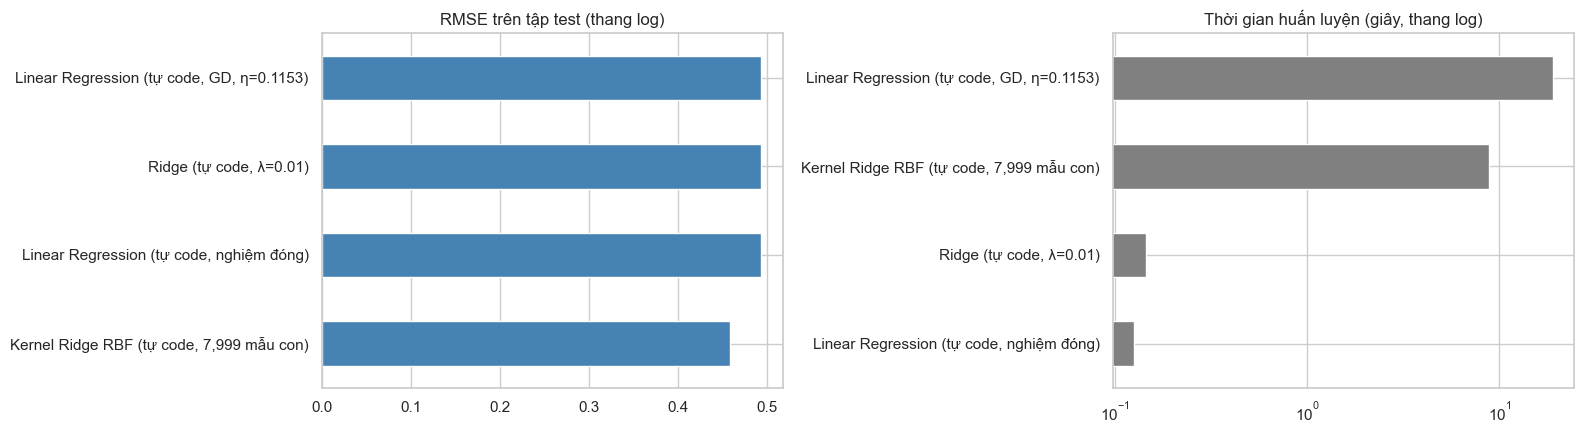

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
bang.drop(index='Mốc so sánh: dự đoán bằng trung bình')['RMSE log'].sort_values().plot(kind='barh', ax=ax[0], color='steelblue')
ax[0].set_title('RMSE trên tập test (thang log)')
bang['Thời gian huấn luyện (s)'].drop(index='Mốc so sánh: dự đoán bằng trung bình').sort_values().plot(kind='barh', ax=ax[1], color='grey', logx=True)
ax[1].set_title('Thời gian huấn luyện (giây, thang log)')
plt.tight_layout(); plt.savefig(f'{FIG}/06_tu_code.png', dpi=120); plt.show()

**Nhận xét:**
- Linear Regression nghiệm đóng, Gradient Descent và Ridge cho kết quả gần như trùng nhau và trùng với scikit-learn (sai khác ~1e-13) → cài đặt đúng. Với hơn 600.000 mẫu và 44 đặc trưng, Ridge gần như không cần phạt (λ tối ưu rất nhỏ) vì mô hình tuyến tính không bị quá khớp.
- Gradient Descent chỉ hội tụ khi η < 2/λmax(H); vượt ngưỡng thì phân kỳ ngay, đúng như lý thuyết.
- Kernel Ridge RBF học được quan hệ phi tuyến nên tốt hơn hẳn mô hình tuyến tính dù chỉ dùng 8.000 mẫu, nhưng chi phí bộ nhớ O(n²) và thời gian O(n³) khiến không thể dùng toàn bộ dữ liệu – đây là lý do notebook 07 dùng thêm các mô hình cây/boosting cho dữ liệu lớn.